# 05 · Evaluación final

**Fase 5 de CRISP-DM.** Desempeño de los dos modelos elegidos en la Fase 4 **solo con validación**
(`config.FINAL_MODEL` = CNN `cnn_estable_1`, `config.FINAL_CLASSIC` = SVM; `docs/crisp-dm.md` §4.3)
sobre los datos que no se usaron para nada antes:

- **`test`**: 4.653 imágenes de Kaggle + HDF (mismas fuentes que entrenamiento, otras frutas).
- **`externa`**: las 81 fotos propias del equipo (otra cámara, otra luz, otras frutas).

La elección quedó registrada en el commit `d7b6928` **antes** de correr esta evaluación, que se
corre una sola vez:

```bash
python -m src.evaluation.evaluate --model cnn_estable_1 --split test --final
python -m src.evaluation.evaluate --model cnn_estable_1 --split externa --final
python -m src.evaluation.evaluate --model svm --split test --final       # y externa
```

Este notebook lee esos resultados (`experiments/results/eval_*.json`) y vuelve a predecir con los
modelos guardados solo para el análisis de errores. KPIs (§1.4): **F1-macro ≥ 0,85** y **recall de
Podrida ≥ 0,90**. Todos los intervalos son IC95 por bootstrap de **grupos** (fotos de la misma fruta).

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src import config  # noqa: E402
from src.evaluation.evaluate import f1_macro, predict, recall_of  # noqa: E402

pd.set_option("display.precision", 3)
C = config.QUALITY_CLASSES
MODELS = {config.FINAL_MODEL: "CNN", config.FINAL_CLASSIC: "SVM"}
SPLITS = ["val", "test", "externa"]
OUT = config.ROOT_DIR / "assets" / "evaluacion"
OUT.mkdir(parents=True, exist_ok=True)


def load_eval(model: str, split: str) -> dict:
    return json.load(open(config.RESULTS_DIR / f"eval_{model}_{split}.json", encoding="utf-8"))


def save(fig, name: str, photos: bool = False) -> None:
    """SVG + PNG; las grillas de fotos solo en PNG a menor resolución (el SVG no aporta nada)."""
    if not photos:
        fig.savefig(OUT / f"{name}.svg", bbox_inches="tight")
    fig.savefig(OUT / f"{name}.png", dpi=110 if photos else 200, bbox_inches="tight")


evals = {(m, s): load_eval(m, s) for m in MODELS for s in SPLITS}

## 1. Resultados frente a los KPIs

In [2]:
def fmt(value, ci):
    return f"{value:.2f} [{ci[0]:.2f}, {ci[1]:.2f}]"


table = pd.DataFrame([{
    "modelo": MODELS[m], "conjunto": s, "imágenes": e["imagenes"], "grupos": e["grupos"],
    "F1-macro [IC95]": fmt(e["f1_macro"], e["ic95"]["f1_macro"]),
    "exactitud [IC95]": fmt(e["accuracy"], e["ic95"]["accuracy"]),
    "recall Podrida [IC95]": fmt(e["por_clase"]["Podrida"]["recall"], e["ic95"]["recall_podrida"]),
    "F1 ≥ 0,85": "sí" if e["f1_macro"] >= 0.85 else "no",
    "recall P ≥ 0,90": "sí" if e["por_clase"]["Podrida"]["recall"] >= 0.90 else "no",
} for (m, s), e in evals.items()])
table

,modelo,conjunto,imágenes,grupos,F1-macro [IC95],exactitud [IC95],recall Podrida [IC95],"F1 ≥ 0,85","recall P ≥ 0,90"
0,CNN,val,4490,1771,"0.91 [0.85, 0.95]","0.94 [0.91, 0.97]","0.94 [0.90, 0.97]",sí,sí
1,CNN,test,4653,1747,"0.80 [0.68, 0.93]","0.88 [0.76, 0.96]","0.91 [0.86, 0.96]",no,sí
2,CNN,externa,81,81,"0.49 [0.37, 0.59]","0.49 [0.38, 0.60]","0.27 [0.11, 0.44]",no,no
3,SVM,val,4490,1771,"0.84 [0.73, 0.92]","0.88 [0.76, 0.95]","0.92 [0.87, 0.96]",no,sí
4,SVM,test,4653,1747,"0.80 [0.73, 0.87]","0.90 [0.85, 0.94]","0.81 [0.75, 0.88]",no,no
5,SVM,externa,81,81,"0.46 [0.35, 0.56]","0.47 [0.36, 0.58]","0.57 [0.40, 0.74]",no,no


Línea base de referencia (clasificador de mayoría: todo `Buena`) en cada conjunto:

In [3]:
preds = {(m, s): predict(m, s) for m in MODELS for s in ["val", "test", "externa"]}
pd.Series({s: f1_macro(preds[(config.FINAL_MODEL, s)][0], np.zeros_like(preds[(config.FINAL_MODEL, s)][0]))
           for s in SPLITS}, name="F1-macro mayoría").to_frame()

/Users/srengifo/Desktop/fruit-quality-classification/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 33 variables whereas the saved optimizer has 37 variables. 
  saveable.load_own_variables(store)
I0000 00:00:1795558683.455822  356019 service.cc:153] XLA service 0x600000ddaa00 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795558683.455833  356019 service.cc:161]   StreamExecutor [0]: Host, Default Version (Driver: 0.0.0; Runtime: 0.0.0; Toolkit: 0.0.0; DNN: 0.0.0)
I0000 00:00:1795558683.459569  356019 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
W0000 00:00:1795558683.548492  356080 cpp_gen_intrinsics.cc:74] Empty bitcode string provided for eigen. Optimizations relying on this IR will be disabled.
I0000 00:00:1795558683.548531  356080 rsqrt.cc:179] Falling back to 1

I0000 00:00:1795558683.576907  356019 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


,F1-macro mayoría
val,0.273
test,0.296
externa,0.171


- **`test`**: los dos modelos quedan en **0,80**, por debajo de la meta de 0,85 y de su F1 de
  validación (CNN 0,91, SVM 0,84). La CNN **sí cumple el recall de Podrida** (0,91); el SVM no (0,82).
  Los intervalos son anchos (CNN 0,69–0,93): unas pocas frutas pesan mucho (§3).
- **Fotos propias**: F1 ≈ 0,46–0,49, muy por encima de la mayoría pero lejos de la meta. La CNN deja
  pasar el 73 % de las Podrida (recall 0,27) → **el sistema no está listo para uso real**. Este es el
  resultado que más importa (§4).

## 2. Matrices de confusión

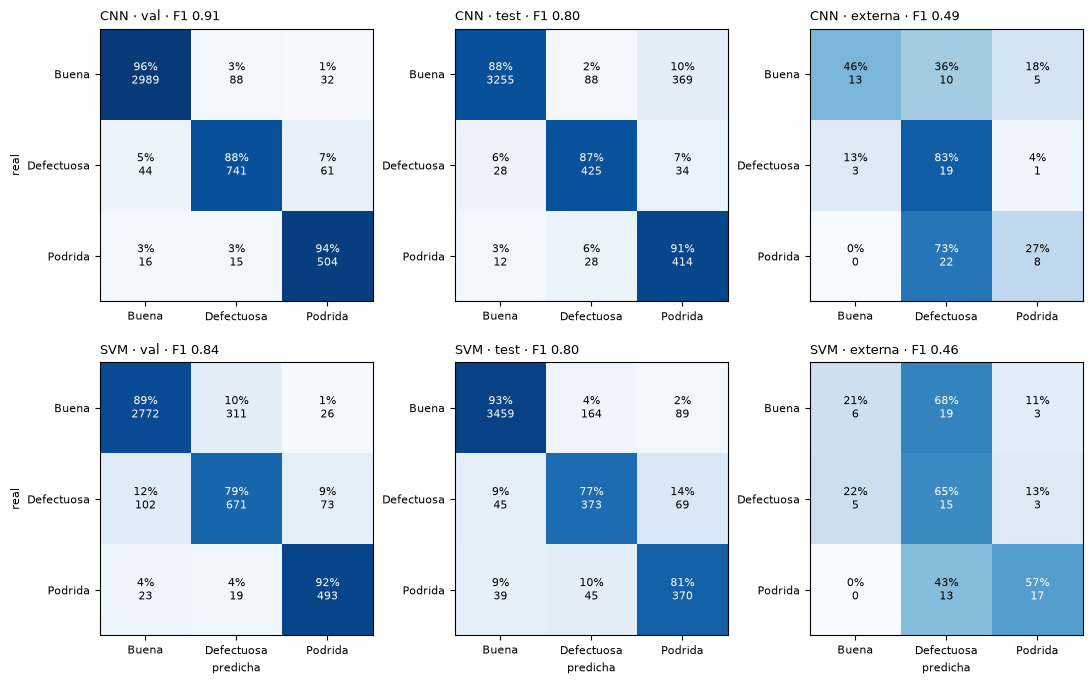

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for row, m in enumerate(MODELS):
    for col, s in enumerate(SPLITS):
        ax = axes[row, col]
        cm = np.array(evals[(m, s)]["matriz_confusion"])
        frac = cm / cm.sum(1, keepdims=True)
        ax.imshow(frac, cmap="Blues", vmin=0, vmax=1)
        for i in range(3):
            for j in range(3):
                ax.text(j, i, f"{frac[i, j]:.0%}\n{cm[i, j]}", ha="center", va="center", fontsize=8,
                        color="white" if frac[i, j] > 0.55 else "black")
        ax.set_xticks(range(3), C, fontsize=8)
        ax.set_yticks(range(3), C, fontsize=8)
        ax.set_title(f"{MODELS[m]} · {s} · F1 {evals[(m, s)]['f1_macro']:.2f}", fontsize=9, loc="left")
        if row == 1:
            ax.set_xlabel("predicha", fontsize=8)
        if col == 0:
            ax.set_ylabel("real", fontsize=8)
plt.tight_layout()
save(fig, "matrices_confusion_final")

- En `test`, el error dominante de la CNN es **Buena → Podrida** (10 % de las Buena, 369 imágenes):
  falsa alarma, el error menos costoso. Podrida → Buena es solo 3 %.
- En las fotos propias, ambos modelos empujan casi todo hacia **Defectuosa**: la CNN clasifica
  22 de 30 Podrida como Defectuosa.

## 3. `test`: ¿por qué baja de 0,91 a 0,80?

In [5]:
y_te, p_te, rows_te = preds[(config.FINAL_MODEL, "test")]
err = pd.DataFrame([{"grupo": r["grupo"], "fuente": r["fuente"], "fruta": r["fruta"],
                     "real": C[t], "predicha": C[p]} for r, t, p in zip(rows_te, y_te, p_te) if t != p])
bp = err[(err.real == "Buena") & (err.predicha == "Podrida")]
print(f"Buena → Podrida: {len(bp)} imágenes en {bp.grupo.nunique()} grupos")
bp.grupo.value_counts().head(5).to_frame("imágenes")

Buena → Podrida: 369 imágenes en 14 grupos


,imágenes
grupo,
external/healthy_defective/apple_images/apple_real_images/fresh/SD_REAL_2072.jpg,306
external/healthy_defective/apple_images/apple_real_images/fresh/SD_REAL_2318.jpg,43
external/healthy_defective/apple_images/apple_real_images/fresh/SD_REAL_0001.jpg,9
raw/Good Quality_Fruits/Apple_Good/20190809150606,1
raw/Good Quality_Fruits/Apple_Good/20190812183417,1


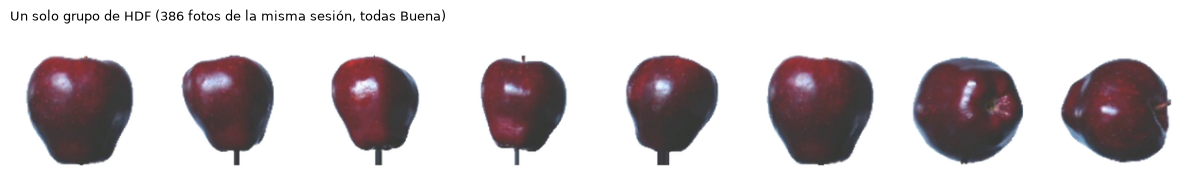

In [6]:
from PIL import Image  # noqa: E402

from src.data.preprocess import cache_path  # noqa: E402

top = bp.grupo.value_counts().index[0]
members = [r for r in rows_te if r["grupo"] == top]
fig, axes = plt.subplots(1, 8, figsize=(12, 1.8))
for ax, r in zip(axes, members[:: max(1, len(members) // 8)]):
    ax.imshow(Image.open(cache_path(r["id"], variant="crop")))
    ax.set_axis_off()
fig.suptitle(f"Un solo grupo de HDF ({len(members)} fotos de la misma sesión, todas Buena)", fontsize=9, x=0.01, ha="left")
plt.tight_layout()

**306 de los 369** errores Buena → Podrida son **una misma sesión de HDF**: manzanas *Red Delicious*
rojo oscuro fotografiadas cientos de veces. La CNN asocia "rojo muy oscuro" con pudrición. Es un
error real (un tipo de fruta que el modelo no entiende) pero, contado por imágenes, una sola fruta
vale como 386.

Para ver el efecto se recalcula el F1 dando a cada **grupo** el mismo peso (cada fruta cuenta una
vez, igual que los pesos de entrenamiento de §3.8). **Advertencia:** esta métrica se decidió
*después* de ver `test`; se reporta como diagnóstico, la cifra oficial sigue siendo la de §1.

In [7]:
from sklearn.metrics import f1_score, recall_score  # noqa: E402


def group_weighted(y, p, rows):
    count = Counter(r["grupo"] for r in rows)
    w = np.array([1 / count[r["grupo"]] for r in rows])
    return (f1_score(y, p, labels=[0, 1, 2], average="macro", sample_weight=w),
            recall_score(y, p, labels=[2], average=None, sample_weight=w)[0])


pd.DataFrame([{"modelo": MODELS[m], "conjunto": s,
               "F1 por imagen": evals[(m, s)]["f1_macro"],
               **dict(zip(["F1 por grupo", "recall Podrida por grupo"], group_weighted(*preds[(m, s)])))}
              for m in MODELS for s in ["val", "test"]])

,modelo,conjunto,F1 por imagen,F1 por grupo,recall Podrida por grupo
0,CNN,val,0.913,0.913,0.919
1,CNN,test,0.802,0.902,0.917
2,SVM,val,0.842,0.882,0.891
3,SVM,test,0.802,0.854,0.829


Contando cada fruta una vez, la CNN da **0,90 en `test` y 0,91 en validación**: el modelo generaliza
a frutas nuevas **de las mismas fuentes**, y la caída de §1 viene de un tipo de manzana concreto que
aparece cientos de veces. El SVM queda por debajo en ambos (0,85).

### Diagnóstico de sobreajuste

In [8]:
classic = json.load(open(config.RESULTS_DIR / "classic.json", encoding="utf-8"))
cnn_run = json.load(open(config.RESULTS_DIR / f"{config.FINAL_MODEL}.json", encoding="utf-8"))
pd.DataFrame({"train": [cnn_run["train"]["f1_macro"], classic["svm"]["train"]["f1_macro"]],
              **{s: [evals[(m, s)]["f1_macro"] for m in MODELS] for s in SPLITS}},
             index=list(MODELS.values()))

,train,val,test,externa
CNN,0.906,0.913,0.802,0.489
SVM,1.000,0.842,0.802,0.459


- **CNN**: train 0,91 ≈ val 0,91 → no memoriza las frutas de entrenamiento (los pesos 1/grupo
  impiden que las sesiones repetidas dominen). La caída está en el **cambio de dominio**, no en el
  sobreajuste clásico.
- **SVM**: train ≫ val/test → sí sobreajusta a las características de entrenamiento.

## 4. Fotos propias: el cambio de dominio

In [9]:
y_ex, p_ex, rows_ex = preds[(config.FINAL_MODEL, "externa")]
_, s_ex, _ = preds[(config.FINAL_CLASSIC, "externa")]
pd.DataFrame({MODELS[m]: {f: v["f1_macro"] for f, v in evals[(m, "externa")]["por_fruta"].items()} for m in MODELS}
             ).assign(imágenes={f: v["imagenes"] for f, v in evals[(config.FINAL_MODEL, "externa")]["por_fruta"].items()})

,CNN,SVM,imágenes
Apple,0.372,0.401,35
Banana,0.635,0.500,11
Guava,0.378,0.083,7
Lime,0.333,0.333,3
Mango,0.533,0.267,9
Orange,0.369,0.253,16


Probabilidad media que asigna la CNN a cada clase, según la clase real:

In [10]:
import tensorflow as tf  # noqa: E402

from src.data.preprocess import load_split  # noqa: E402

cnn = tf.keras.models.load_model(config.CHECKPOINTS_DIR / f"{config.FINAL_MODEL}.keras")
X_ex, _ = load_split("externa")
prob_ex = cnn.predict(X_ex, verbose=0)
pd.DataFrame([prob_ex[y_ex == c].mean(0) for c in range(3)], index=[f"real {c}" for c in C],
             columns=[f"P({c})" for c in C])

/Users/srengifo/Desktop/fruit-quality-classification/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 33 variables whereas the saved optimizer has 37 variables. 
  saveable.load_own_variables(store)


,P(Buena),P(Defectuosa),P(Podrida)
real Buena,0.398,0.407,0.194
real Defectuosa,0.180,0.739,0.081
real Podrida,0.013,0.742,0.245


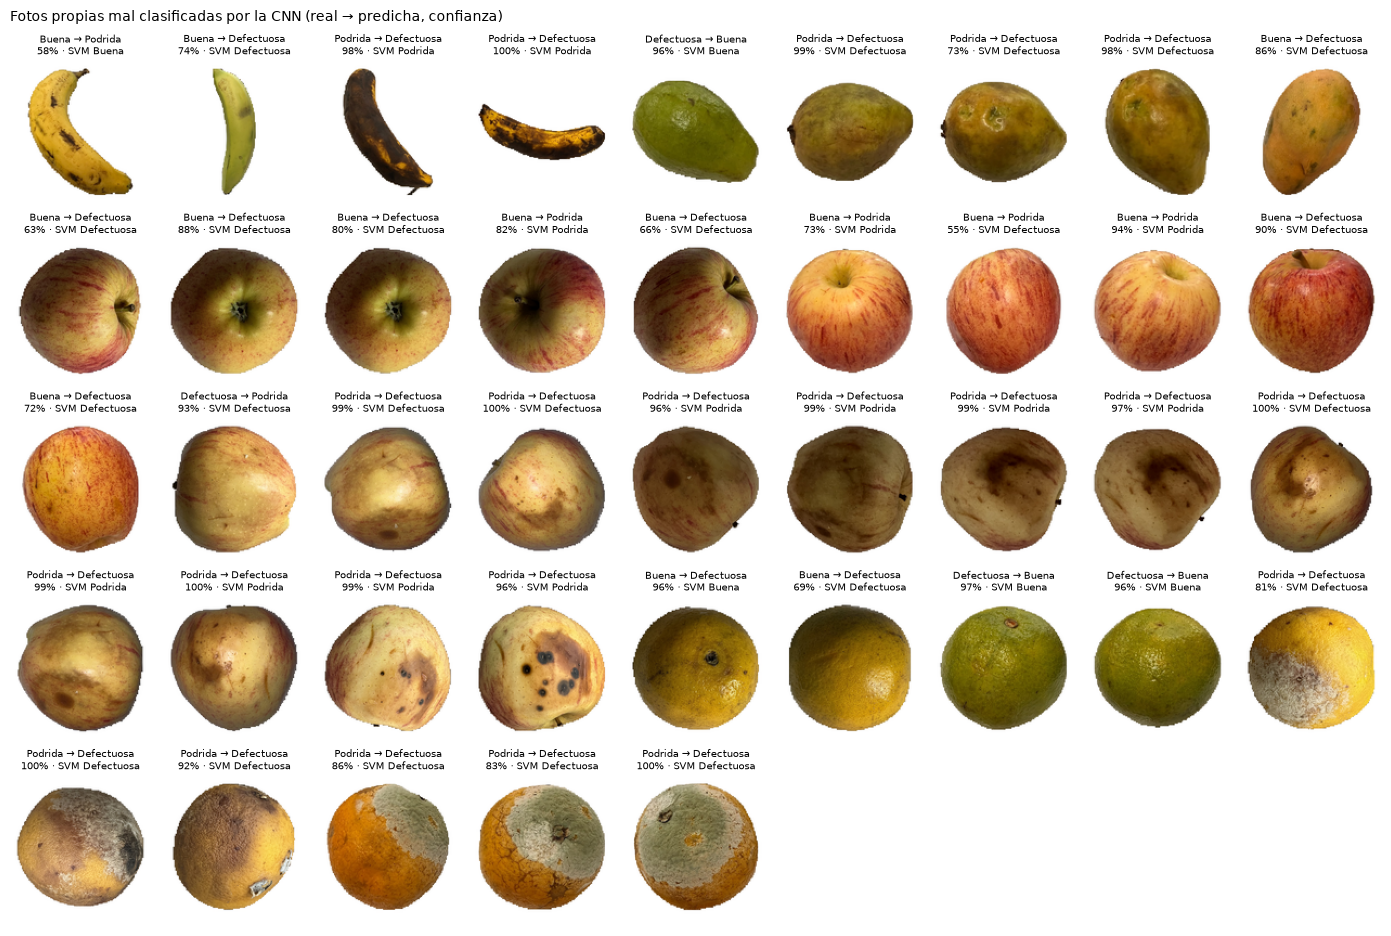

In [11]:
wrong = np.flatnonzero(p_ex != y_ex)
n_cols = 9
fig, axes = plt.subplots(int(np.ceil(len(wrong) / n_cols)), n_cols, figsize=(14, 1.9 * np.ceil(len(wrong) / n_cols)))
for ax in axes.flat:
    ax.set_axis_off()
for ax, i in zip(axes.flat, wrong):
    ax.imshow(X_ex[i])
    ax.set_title(f"{rows_ex[i]['calidad']} → {C[p_ex[i]]}\n{prob_ex[i].max():.0%} · SVM {C[s_ex[i]]}", fontsize=7)
fig.suptitle("Fotos propias mal clasificadas por la CNN (real → predicha, confianza)", fontsize=10, x=0.01, ha="left")
plt.tight_layout()
save(fig, "errores_fotos_propias", photos=True)

Patrones de error (revisión visual):

1. **Podrida → Defectuosa** es el error principal (22 de 30 Podrida): 11 de 14 manzanas, 6
   naranjas con moho, 3 guayabas y 2 bananos. Las manzanas tienen zonas marrones hundidas grandes,
   que según `docs/criterios_anotacion.md` son Podrida; en el entrenamiento las manzanas Podrida
   (sobre todo de HDF) son casos más extremos → el modelo aprendió **otro umbral** de pudrición que
   el de nuestro criterio. La naranja ya era la fruta más débil en validación (F1 0,65) y en `test`
   (0,58).
2. **Manzanas buenas → Defectuosa (6) o Podrida (4).** Son de una variedad rayada rojo/amarilla
   (tipo Gala), rara en el entrenamiento: el rayado se confunde con manchas. Es el mismo tipo de
   error que las Red Delicious de `test` (§3): la variedad de manzana cambia el color "normal".
3. Los errores llegan casi siempre con **confianza > 90 %**: la probabilidad de la CNN no sirve
   como alarma de "no sé" fuera de su dominio.

Limitaciones de esta evaluación: solo 81 fotos y varias son **la misma fruta** desde otro ángulo
(no está anotado), así que el IC95 real es más ancho que el reportado; las frutas no cubren por
igual las 3 clases.

### ROC-AUC de la CNN (uno contra el resto)

Mide si las probabilidades **ordenan** bien las clases, independientemente del umbral (el SVM no
entrega probabilidades).

In [12]:
from sklearn.metrics import roc_auc_score  # noqa: E402

X_te, _ = load_split("test")
prob_te = cnn.predict(X_te, batch_size=256, verbose=0)
pd.DataFrame({s: {c: roc_auc_score(y == k, p[:, k]) for k, c in enumerate(C)}
              for s, (y, p) in {"test": (y_te, prob_te), "externa": (y_ex, prob_ex)}.items()}).T

,Buena,Defectuosa,Podrida
test,0.971,0.972,0.963
externa,0.811,0.597,0.592


## 5. Conclusiones de la evaluación

- **Dentro de las fuentes conocidas el problema está resuelto razonablemente:** la CNN desde cero
  alcanza F1 0,90 contando cada fruta una vez y recall de Podrida 0,91 en `test` (cumple ese KPI),
  y supera al SVM. Por imagen, `test` da 0,80 por un solo tipo de manzana sobrerrepresentado.
- **Fuera de esas fuentes no:** con las fotos del equipo el F1 cae a ~0,49 y la CNN deja pasar la
  mayoría de la fruta podrida. La causa principal no es el sobreajuste sino el **cambio de dominio**
  (variedades, cámara, luz) y un **umbral de pudrición distinto** entre las etiquetas de los
  datasets públicos y nuestro criterio.
- El hallazgo coincide con la prueba entre fuentes de la Fase 4 (Kaggle ↔ HDF, F1 0,06–0,42): cada
  conjunto de imágenes es un dominio distinto.

**Qué haría falta para usarlo de verdad** (no se puede hacer con las fotos propias actuales sin
contaminar la evaluación): fotografiar más fruta propia y usar una parte para entrenar o ajustar
(manteniendo otra parte, de **otras frutas**, como prueba), alinear el criterio Defectuosa/Podrida
en las etiquetas de entrenamiento y agregar una opción de "no sé" para fotos fuera de dominio.

## 6. Iteraciones posteriores: segunda y tercera mirada a las fotos propias

Las fotos propias son la prueba que importa, pero **cada vez que se usan dejan de ser nuevas**: se
registra cuántas veces se miraron y con qué modelo fijado antes.

| Mirada | Modelo | Qué cambió | Fijado en |
|---|---|---|---|
| 1.ª | CNN `cnn_estable_1`, SVM | — (Fase 5) | commit `d7b6928` |
| 2.ª | Transfer `tl_busqueda_4` (EfficientNetB0 + color + FruQ) | modelo preentrenado y fuente FruQ (§4.5) | commit `8818bb0` |
| 3.ª | `v3_0` (CNN) y `v3_1` (transfer), misma configuración | **etiquetas revisadas** y sin imágenes de varias frutas (`index_v3.csv`, `02_preprocessing` §8) | commit `4bac7a8` |

Los modelos `v3_*` se entrenaron en Colab (búsqueda `v3` de `src/models/transfer.py`) y se evaluaron
**solo** con las fotos propias: `test` cambió de etiquetas en v3, así que su cifra no sería
comparable con las anteriores.

In [13]:
ITER = {"cnn_estable_1": "CNN · original", "v3_0": "CNN · v3",
        "tl_busqueda_4": "Transfer · original", "v3_1": "Transfer · v3"}
pd.DataFrame({ITER[m]: {"F1-macro": e["f1_macro"], "IC95": "[{:.2f}; {:.2f}]".format(*e["ic95"]["f1_macro"]),
                        "recall Podrida": e["por_clase"]["Podrida"]["recall"],
                        "Podrida → Defectuosa": e["matriz_confusion"][2][1]}
              for m in ITER for e in [load_eval(m, "externa")]}).T

,F1-macro,IC95,recall Podrida,Podrida → Defectuosa
CNN · original,0.489,[0.37; 0.59],0.267,22
CNN · v3,0.383,[0.27; 0.49],0.133,26
Transfer · original,0.472,[0.36; 0.57],0.3,20
Transfer · v3,0.517,[0.40; 0.62],0.267,21


Diferencias **pareadas** (mismas 81 fotos, bootstrap por grupos): `original − v3`.

In [14]:
from src.evaluation.evaluate import paired_diff_ci  # noqa: E402

preds = {m: predict(m, "externa") for m in ITER}
y_ex3, _, rows_ex3 = preds["v3_0"]
groups_ex3 = [r["grupo"] for r in rows_ex3]
podrida = C.index("Podrida")
pd.DataFrame({f"{ITER[a]} − {ITER[b]}": {
    name: "{:+.3f} [{:+.3f}; {:+.3f}]".format(*paired_diff_ci(y_ex3, preds[a][1], preds[b][1], groups_ex3, metric))
    for name, metric in {"F1-macro": f1_macro, "recall Podrida": recall_of(podrida)}.items()}
    for a, b in [("cnn_estable_1", "v3_0"), ("tl_busqueda_4", "v3_1")]}).T

/Users/srengifo/Desktop/fruit-quality-classification/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 33 variables whereas the saved optimizer has 37 variables. 
  saveable.load_own_variables(store)


/Users/srengifo/Desktop/fruit-quality-classification/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 427 variables whereas the saved optimizer has 431 variables. 
  saveable.load_own_variables(store)


,F1-macro,recall Podrida
CNN · original − CNN · v3,+0.106 [+0.003; +0.216],+0.133 [-0.040; +0.318]
Transfer · original − Transfer · v3,-0.045 [-0.150; +0.061],+0.033 [-0.136; +0.212]


¿Los modelos v3 aprendieron mejor sus propias etiquetas? Las **mismas** imágenes de validación
(las que siguen en v3), calificadas con las etiquetas originales y con las revisadas:

In [15]:
from src.data.preprocess import load_split  # noqa: E402
from tensorflow import keras  # noqa: E402

X_va3, rows_va3 = load_split("val", config.DATASET_INDEX_V3)
original_label = pd.read_csv(config.DATASET_INDEX).set_index("id")["calidad"]
y_v3 = np.array([C.index(r["calidad"]) for r in rows_va3])
y_v1 = np.array([C.index(original_label[r["id"]]) for r in rows_va3])
cross = {}
for m in ITER:
    p = keras.models.load_model(config.CHECKPOINTS_DIR / f"{m}.keras").predict(X_va3, batch_size=256, verbose=0).argmax(1)
    cross[ITER[m]] = {"F1 con etiquetas originales": f1_macro(y_v1, p), "F1 con etiquetas v3": f1_macro(y_v3, p)}
print(len(rows_va3), "imágenes de validación")
pd.DataFrame(cross).T

/Users/srengifo/Desktop/fruit-quality-classification/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 33 variables whereas the saved optimizer has 37 variables. 
  saveable.load_own_variables(store)


/Users/srengifo/Desktop/fruit-quality-classification/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 33 variables whereas the saved optimizer has 37 variables. 
  saveable.load_own_variables(store)


/Users/srengifo/Desktop/fruit-quality-classification/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 427 variables whereas the saved optimizer has 431 variables. 
  saveable.load_own_variables(store)


/Users/srengifo/Desktop/fruit-quality-classification/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 427 variables whereas the saved optimizer has 431 variables. 
  saveable.load_own_variables(store)


4013 imágenes de validación


,F1 con etiquetas originales,F1 con etiquetas v3
CNN · original,0.910,0.800
CNN · v3,0.733,0.761
Transfer · original,0.912,0.802
Transfer · v3,0.753,0.825


### Conclusión de la tercera iteración (resultado negativo)

- **No mejoró la generalización.** La CNN v3 empeora con las fotos propias (−0,11 de F1, IC95 sin
  cero); el transfer v3 sube +0,045, pero el IC95 incluye el cero. El recall de Podrida no mejora:
  el transfer v3 sigue mandando 21 de 30 podridas a Defectuosa (la CNN v3, 26 de 30).
- **Por qué:** la revisión hizo Podrida *más* exigente (945 imágenes Podrida → Defectuosa), así que
  los modelos aprendieron que "podrido" es "muy podrido", justo el sesgo que se quería corregir. Y
  ni siquiera con sus propias etiquetas los modelos v3 superan a los originales con claridad: las
  etiquetas revisadas no son más fáciles de aprender.
- **Lo que sí deja:** el acuerdo entre anotadores en Kaggle es κ = 0,29. La frontera
  Defectuosa/Podrida no está bien definida ni con el criterio escrito: el cuello de botella es la
  **definición de la clase**, no la cantidad de datos ni la arquitectura.
- **Decisión:** los modelos finales no cambian (`config.FINAL_MODEL`, `config.FINAL_TRANSFER`).

## 7. Cuarta iteración: solo manzana, banano y naranja, y fotos nuevas

Plan fijado antes de entrenar (commit `7de73d9`, `docs/crisp-dm.md` §3.12): transfer final con 3
frutas, con etiquetas originales (`v4_0`) o v4 (`v4_1`), frente al modelo actual de la app. Se evalúa
en las **35 fotos nuevas** del 24 nov. (primera mirada, camino de la app) y en las 81 anteriores
**restringidas a las 3 frutas** (cuarta mirada). Resultados de `python -m src.evaluation.iteracion4`.

In [16]:
it4 = json.load(open(config.RESULTS_DIR / "iteracion4.json", encoding="utf-8"))
pd.DataFrame({m: {"Buena → Buena": r["buena_como_buena"], "IC95": "[{:.2f}; {:.2f}]".format(*r["recall_buena_ic95"]),
                  "Podrida detectada como dañada": r["podrida_detectada_como_danada"],
                  "Podrida → Podrida": r["podrida_como_podrida"], "limones (fuera de alcance)": it4["nov24_limon"][m]}
              for m, r in it4["nov24"].items()}).T

,Buena → Buena,IC95,Podrida detectada como dañada,Podrida → Podrida,limones (fuera de alcance)
tl_busqueda_4,21/26,[0.65; 0.92],6/6,2/6,"[Buena, Buena, Buena]"
v4_0,20/26,[0.62; 0.92],5/6,4/6,"[Buena, Buena, Buena]"
v4_1,21/26,[0.65; 0.92],6/6,3/6,"[Buena, Buena, Buena]"


In [17]:
fmt = "{:+.3f} [{:+.3f}; {:+.3f}]".format
base = it4["modelos"][0]
pd.DataFrame({m: {"F1-macro": r["f1_macro"], "recall Podrida": r["recall_podrida"],
                  "Δ F1 vs actual": fmt(*r[f"dif_f1_vs_{base}"]) if m != base else "—",
                  "Δ recall Podrida vs actual": fmt(*r[f"dif_recall_podrida_vs_{base}"]) if m != base else "—"}
              for m, r in it4["externa_3_frutas"].items()}).T

,F1-macro,recall Podrida,Δ F1 vs actual,Δ recall Podrida vs actual
tl_busqueda_4,0.416,0.296,—,—
v4_0,0.467,0.481,+0.050 [-0.056; +0.154],+0.185 [+0.043; +0.345]
v4_1,0.512,0.37,+0.096 [-0.012; +0.213],+0.074 [-0.100; +0.250]


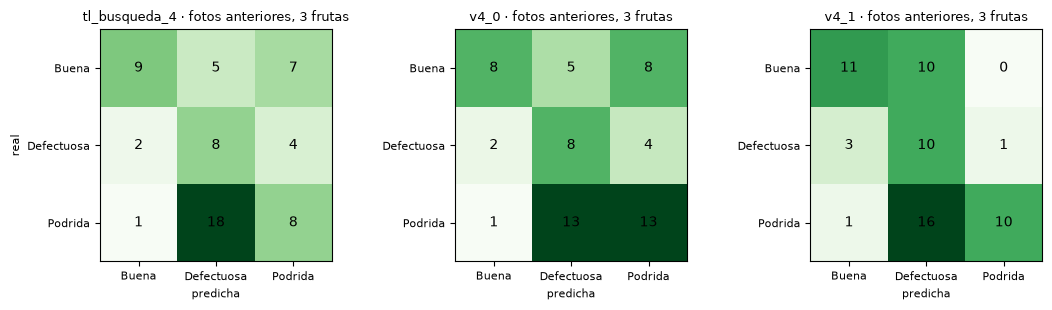

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, (m, r) in zip(axes, it4["externa_3_frutas"].items()):
    cm = np.array(r["matriz_confusion"])
    ax.imshow(cm, cmap="Greens")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10)
    ax.set_xticks(range(3), C, fontsize=8)
    ax.set_yticks(range(3), C, fontsize=8)
    ax.set_title(f"{m} · fotos anteriores, 3 frutas", fontsize=9)
    ax.set_xlabel("predicha", fontsize=8)
axes[0].set_ylabel("real", fontsize=8)
plt.tight_layout()
save(fig, "iteracion4_matrices")

- **Fotos nuevas:** los tres modelos detectan como dañadas casi todas las podridas y reconocen ~80 %
  de las buenas; con 6 podridas no hay diferencias demostrables. Los 6 bananos se aciertan siempre.
  Errores comunes: manzanas buenas rayadas y naranjas verdes con cicatrices → Defectuosa.
- **Fotos anteriores (3 frutas):** recortar el alcance sube el recall de Podrida (`v4_0`: +0,19,
  IC sin cero); `v4_1` tiene el mejor F1 (+0,10, IC toca el cero) y ninguna falsa alarma
  Buena → Podrida.
- **Conclusión:** tendencia favorable pero modesta; es un cambio de **alcance** (3 frutas), no un
  modelo mejor para las 6 frutas. **Decisión del equipo:** se mantiene `tl_busqueda_4` como modelo de
  la app; `v4` queda como experimento documentado.